# Исследование нейронной сети на TensorFlow

**Цель работы:** разработка и исследование полносвязной нейронной сети для решения задачи бинарной классификации пассажиров Titanic с использованием TensorFlow и Keras.

В ходе исследования предполагается построить базовую нейронную сеть, изучить влияние количества эпох, размера батча, архитектуры сети и функций активации на качество классификации.

Для оценки эффективности модели будут использоваться метрики Accuracy, Precision, Recall, F1-score и ROC-AUC. Процесс обучения будет визуализироваться с помощью графиков изменения функции потерь и точности на обучающей и валидационной выборках, а также инструмента TensorBoard.

In [60]:
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import matplotlib.pyplot as plt
from itertools import product
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

In [61]:
data = pd.read_csv('Titanic-Dataset.csv')

print('Размерность датасета:', data.shape)

Размерность датасета: (891, 12)


### Предобработка данных

In [62]:
X = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived'])
y = data['Survived']

print("Размерность X:", X.shape)
print("Размерность y:", y.shape)
print("\nВыбранные признаки:")
print(X.columns.tolist())

Размерность X: (891, 7)
Размерность y: (891,)

Выбранные признаки:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=67,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (712, 7)
Тестовая выборка: (179, 7)


In [64]:
age_imputer = SimpleImputer(strategy='median')
embarked_imputer = SimpleImputer(strategy='most_frequent')

X_train['Age'] = age_imputer.fit_transform(X_train[['Age']]).ravel()
X_test['Age'] = age_imputer.transform(X_test[['Age']]).ravel()

X_train['Embarked'] = embarked_imputer.fit_transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

print("Пропуски в обучающей выборке:", X_train.isnull().sum().sum())
print("Пропуски в тестовой выборке:", X_test.isnull().sum().sum())

Пропуски в обучающей выборке: 0
Пропуски в тестовой выборке: 0


In [65]:
X_train['Sex'] = X_train['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

categorical_cols = ['Pclass', 'Embarked']

train_encoded = encoder.fit_transform(X_train[categorical_cols])
test_encoded = encoder.transform(X_test[categorical_cols])

encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train = pd.concat([
    X_train.drop(columns=categorical_cols),
    pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
], axis=1)

X_test = pd.concat([
    X_test.drop(columns=categorical_cols),
    pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test.index)
], axis=1)

print("Размерность обучающей выборки:", X_train.shape)
print("Размерность тестовой выборки:", X_test.shape)

display(X_train.head())

Размерность обучающей выборки: (712, 11)
Размерность тестовой выборки: (179, 11)


,Sex,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S
90,0,29.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0
551,0,27.0,0,0,26.0000,0.0,1.0,0.0,0.0,0.0,1.0
192,1,19.0,1,0,7.8542,0.0,0.0,1.0,0.0,0.0,1.0
95,0,29.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0
668,0,43.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0


### Создание валидационной выборки

Для настройки гиперпараметров нейронной сети исходная обучающая выборка дополнительно разделяется на обучающую и валидационную части в соотношении 80/20.

Обучающая выборка используется для обновления весов нейронной сети, а валидационная — для оценки качества модели в процессе обучения и выбора оптимальных гиперпараметров.

Тестовая выборка остаётся неизменной и используется только для окончательной оценки качества выбранной модели.

In [66]:
X_train_nn, X_val, y_train_nn, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=67,
    stratify=y_train
)

print("Обучающая выборка:", X_train_nn.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (569, 11)
Валидационная выборка: (143, 11)
Тестовая выборка: (179, 11)


### Стандартизация признаков

Перед обучением нейронной сети выполняется стандартизация признаков методом Z-score с использованием StandardScaler.

Стандартизированное значение признака рассчитывается по формуле:

$$
z = \frac{x - \mu}{\sigma}
$$

где:
- $x$ — исходное значение признака;
- $\mu$ — среднее значение признака;
- $\sigma$ — стандартное отклонение признака.

В результате стандартизации признаки обучающей выборки приобретают среднее значение, близкое к 0, и стандартное отклонение, близкое к 1.

Параметры стандартизации рассчитываются исключительно на обучающей выборке и затем применяются к валидационной и тестовой выборкам. Это позволяет избежать утечки информации при масштабировании данных.

In [67]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_nn)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## Создание базовой нейронной сети

Для решения задачи бинарной классификации используется полносвязная нейронная сеть (Multilayer Perceptron, MLP), реализованная средствами TensorFlow и Keras.

Архитектура сети включает входной слой с 11 признаками, два скрытых полносвязных слоя с 32 и 16 нейронами соответственно и выходной слой с одним нейроном.

В скрытых слоях применяется функция активации ReLU:

$$
f(x) = \max(0, x)
$$

На выходном слое используется функция Sigmoid:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

Функция Sigmoid преобразует выход нейронной сети в значение от 0 до 1, интерпретируемое как вероятность принадлежности пассажира к классу выживших.

In [68]:
tf.keras.utils.set_random_seed(67)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

### Настройка функции потерь и оптимизатора

Для обучения нейронной сети используется функция потерь Binary Crossentropy, предназначенная для задач бинарной классификации:

$$
L = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

где:
- $N$ — количество объектов;
- $y_i$ — истинное значение класса (0 или 1);
- $p_i$ — предсказанная вероятность принадлежности к положительному классу.

Минимизация данной функции позволяет приблизить предсказанные вероятности к истинным значениям классов.

Для оптимизации весов применяется алгоритм Adam с начальной скоростью обучения 0,001. Adam использует адаптивные оценки первого и второго моментов градиента для обновления параметров модели.

В качестве метрики, отслеживаемой в процессе обучения, используется Accuracy — доля правильно классифицированных объектов.

In [69]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### Обучение базовой нейронной сети

Обучение нейронной сети выполняется на обучающей выборке, содержащей 569 объектов. Для контроля качества используется валидационная выборка из 143 объектов.

В качестве начальных гиперпараметров выбраны 50 эпох и размер батча 32.

**Эпоха (epoch)** — один полный проход нейронной сети по обучающей выборке.

**Размер батча (batch size)** — количество обучающих объектов, после обработки которых выполняется одно обновление весов модели.

В процессе обучения отслеживаются значения функции потерь (Loss) и точности классификации (Accuracy) на обучающей и валидационной выборках. Это позволяет оценить динамику обучения и выявить возможные признаки переобучения.

In [70]:
history = model.fit(
    X_train_scaled,
    y_train_nn,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=1
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6221 - loss: 0.6686 - val_accuracy: 0.6573 - val_loss: 0.6362
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7153 - loss: 0.6016 - val_accuracy: 0.7203 - val_loss: 0.5922
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7821 - loss: 0.5511 - val_accuracy: 0.7622 - val_loss: 0.5551
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7944 - loss: 0.5103 - val_accuracy: 0.8182 - val_loss: 0.5226
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8190 - loss: 0.4779 - val_accuracy: 0.8392 - val_loss: 0.4975
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8313 - loss: 0.4528 - val_accuracy: 0.8322 - val_loss: 0.4778
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8330 - loss: 0.4340 - val_accuracy: 0.8322 - val_loss: 0.4640
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8366 - loss: 0.4204 - val_accuracy: 0.8322 - val_loss

In [71]:
print("Последняя эпоха:")
print(f"Training Loss: {history.history['loss'][-1]:.4f}")
print(f"Validation Loss: {history.history['val_loss'][-1]:.4f}")
print(f"Training Accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")

Последняя эпоха:
Training Loss: 0.3468
Validation Loss: 0.4684
Training Accuracy: 0.8612
Validation Accuracy: 0.8042


### Анализ результатов обучения базовой модели

После 50 эпох обучения точность нейронной сети на обучающей выборке составила 86,12%, а на валидационной — 80,42%.

Значение функции потерь на обучающей выборке составило 0,3468, на валидационной — 0,4684.

Разница между показателями качества на обучающей и валидационной выборках указывает на возможное переобучение модели. Для более подробного анализа необходимо исследовать динамику изменения функции потерь и точности классификации в процессе обучения.

# Мониторинг обучения с помощью TensorBoard

Загрузка расширения TensorBoard в Jupyter Notebook

In [73]:
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Настройка записи логов

In [74]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir='logs/tensorboard/baseline',
    histogram_freq=1
)

Создание модели

In [75]:
tf.keras.utils.set_random_seed(67)

model_tb = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_tb.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Обучение с записью логов

In [76]:
history_tb = model_tb.fit(
    X_train_scaled,
    y_train_nn,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    callbacks=[tensorboard_callback],
    verbose=1
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6221 - loss: 0.6686 - val_accuracy: 0.6573 - val_loss: 0.6362
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7153 - loss: 0.6016 - val_accuracy: 0.7203 - val_loss: 0.5922
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7821 - loss: 0.5511 - val_accuracy: 0.7622 - val_loss: 0.5551
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7944 - loss: 0.5103 - val_accuracy: 0.8182 - val_loss: 0.5226
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8190 - loss: 0.4779 - val_accuracy: 0.8392 - val_loss: 0.4975
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8313 - loss: 0.4528 - val_accuracy: 0.8322 - val_loss: 0.4778
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8330 - loss: 0.4340 - val_accuracy: 0.8322 - val_loss: 0.4640
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8366 - loss: 0.4204 - val_accuracy: 0.8322 - val_loss

На представленных графиках отображается изменение указанных метрик в зависимости от количества эпох обучения.

Изменение точности классификации в TensorBoard

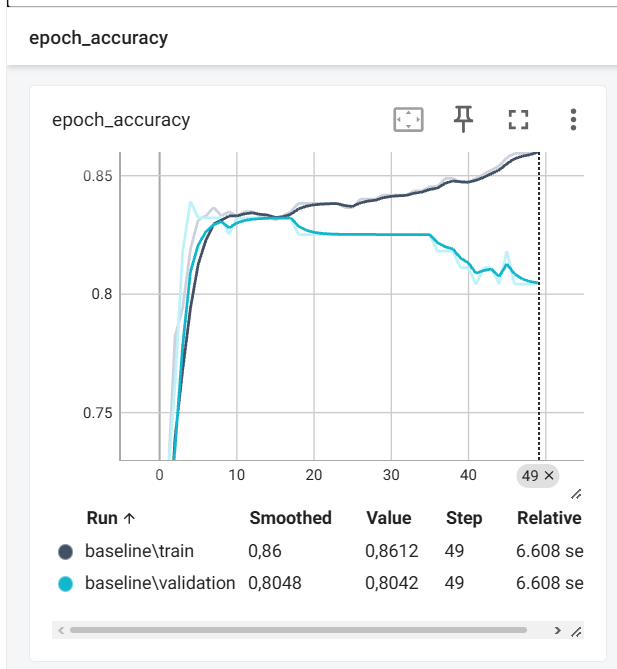

Изменение функции потерь в TensorBoard

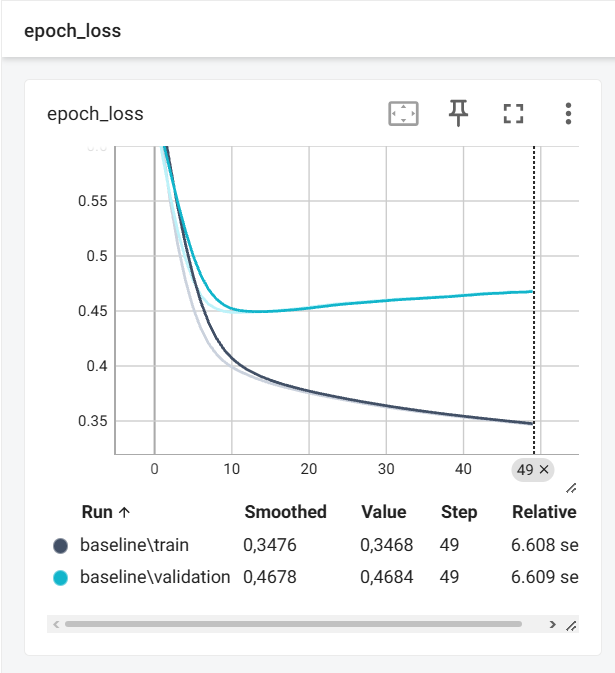

### Вывод

По результатам визуализации установлено, что в процессе обучения точность классификации на обучающей выборке постепенно увеличивается, а значение функции потерь уменьшается.

На валидационной выборке улучшение показателей наблюдается преимущественно в течение первых 10–12 эпох. При дальнейшем обучении функция потерь начинает возрастать, а точность классификации перестаёт улучшаться, что свидетельствует о признаках переобучения.

Таким образом, увеличение количества эпох не всегда приводит к повышению качества классификации. Полученные результаты подтверждают необходимость дальнейшего исследования гиперпараметров нейронной сети.

# Исследование влияния количества эпох

Для оценки влияния количества эпох на качество классификации проводится серия экспериментов с различной продолжительностью обучения нейронной сети.

Рассматриваются следующие значения гиперпараметра epochs: 10, 25, 50 и 100.

Во всех экспериментах используется одинаковая архитектура нейронной сети с двумя скрытыми слоями (32 и 16 нейронов), функцией активации ReLU, оптимизатором Adam и размером батча 32.

In [77]:
epoch_values = [10, 25, 50, 100]
epoch_results = []

for n_epochs in epoch_values:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(67)

    model_exp = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model_exp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f'logs/tensorboard/epochs/{n_epochs}',
        histogram_freq=1
    )

    history_exp = model_exp.fit(
        X_train_scaled,
        y_train_nn,
        epochs=n_epochs,
        batch_size=32,
        validation_data=(X_val_scaled, y_val),
        callbacks=[callback],
        verbose=0
    )

    epoch_results.append({
        'Эпохи': n_epochs,
        'Train Accuracy': history_exp.history['accuracy'][-1],
        'Validation Accuracy': history_exp.history['val_accuracy'][-1],
        'Train Loss': history_exp.history['loss'][-1],
        'Validation Loss': history_exp.history['val_loss'][-1]
    })

epoch_results_df = pd.DataFrame(epoch_results)
display(epoch_results_df.round(4))

,Эпохи,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,10,0.8348,0.8252,0.4040,0.4497
1,25,0.8366,0.8252,0.3699,0.4567
2,50,0.8612,0.8042,0.3468,0.4684
3,100,0.8717,0.8322,0.3160,0.4863


Изменение точности классификации на валидационной выборке при различном количестве эпох обучения.

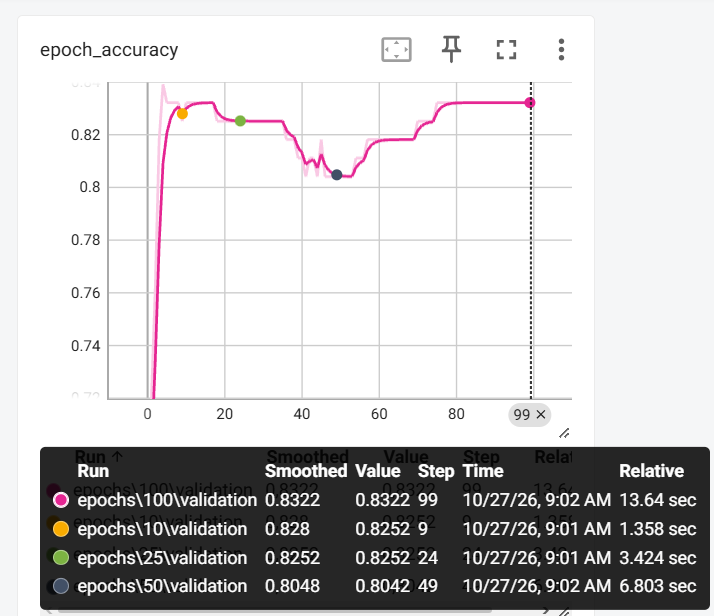

Изменение функции потерь на валидационной выборке при различном количестве эпох обучения.

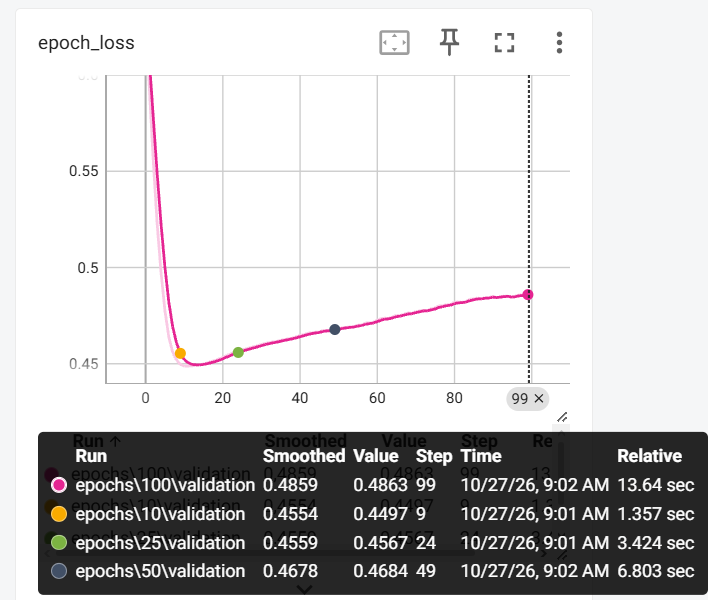

### Вывод

Увеличение количества эпох приводит к постепенному повышению точности на обучающей выборке с 0.8348 до 0.8717 и снижению функции потерь с 0.4040 до 0.3160.

На валидационной выборке аналогичной закономерности не наблюдается. Максимальная итоговая точность классификации 0.8322 достигнута при 100 эпохах, однако минимальное значение функции потерь 0.4497 получено при 10 эпохах. При дальнейшем увеличении продолжительности обучения Validation Loss возрастает до 0.4863, что свидетельствует о признаках переобучения.

Таким образом, увеличение количества эпох не гарантирует улучшения обобщающей способности нейронной сети. Обучение в течение 10 эпох обеспечивает сопоставимую точность классификации при меньших потерях и вычислительных затратах. 



# Исследование влияния размера батча

Для оценки влияния размера батча на качество классификации проводится серия экспериментов со значениями batch_size: 16, 32, 64 и 128.

Во всех экспериментах используется одинаковая архитектура нейронной сети с двумя скрытыми слоями (32 и 16 нейронов), функцией активации ReLU, оптимизатором Adam и количеством эпох обучения 50.

In [78]:
batch_values = [16, 32, 64, 128]
batch_results = []

for batch in batch_values:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(67)

    model_exp = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model_exp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f'logs/tensorboard/batch_size/{batch}',
        histogram_freq=1
    )

    history_exp = model_exp.fit(
        X_train_scaled,
        y_train_nn,
        epochs=50,
        batch_size=batch,
        validation_data=(X_val_scaled, y_val),
        callbacks=[callback],
        verbose=0
    )

    batch_results.append({
        'Batch Size': batch,
        'Train Accuracy': history_exp.history['accuracy'][-1],
        'Validation Accuracy': history_exp.history['val_accuracy'][-1],
        'Train Loss': history_exp.history['loss'][-1],
        'Validation Loss': history_exp.history['val_loss'][-1]
    })

batch_results_df = pd.DataFrame(batch_results)
display(batch_results_df.round(4))

,Batch Size,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,16,0.8629,0.8112,0.3369,0.4787
1,32,0.8612,0.8042,0.3468,0.4684
2,64,0.8418,0.8182,0.3597,0.4623
3,128,0.8401,0.8252,0.3737,0.4530


Изменение точности классификации на валидационной выборке при различных размерах батча.

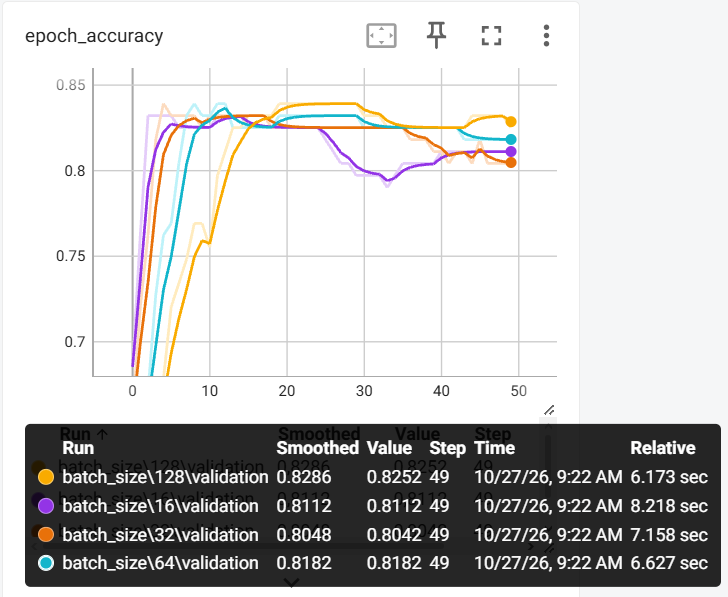

Изменение функции потерь на валидационной выборке при различных размерах батча.

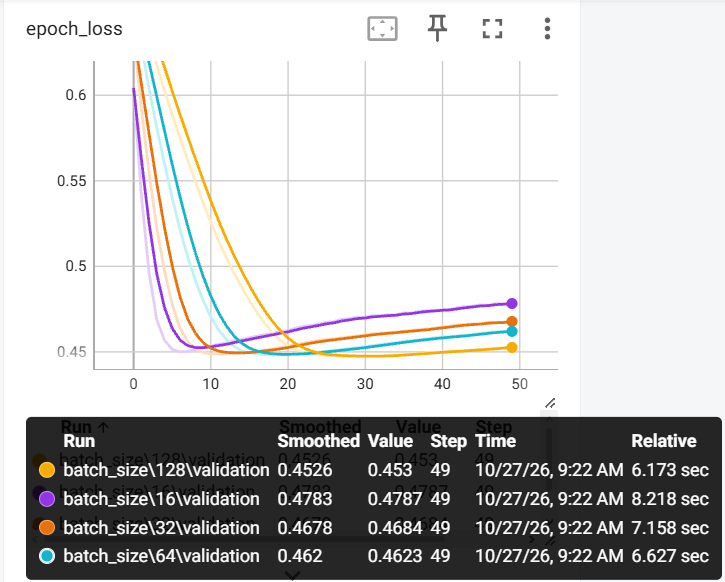

### Вывод

Увеличение размера батча сопровождается снижением точности на обучающей выборке с 0.8629 до 0.8401 и увеличением функции потерь с 0.3369 до 0.3737.

При этом на валидационной выборке наблюдается противоположная тенденция: точность классификации увеличивается с 0.8112 до 0.8252, а значение функции потерь уменьшается с 0.4787 до 0.4530.

Таким образом, в рамках проведённых экспериментов наилучшие показатели на валидационной выборке получены при размере батча 128. Данное значение рассматривается как наиболее предпочтительное среди исследованных, поскольку обеспечивает максимальную валидационную точность и минимальные потери.

# Исследование влияния архитектуры нейронной сети

Для оценки влияния архитектуры на качество классификации проводится серия экспериментов с различным количеством скрытых слоёв и нейронов.

Рассматриваются шесть конфигураций: (16), (32), (32, 16), (64, 32), (64, 32, 16) и (128, 64, 32).

Во всех экспериментах используются одинаковые параметры обучения: 50 эпох, размер батча 32, функция активации ReLU и оптимизатор Adam с коэффициентом скорости обучения 0.001.

Для каждой архитектуры создаётся отдельная нейронная сеть. Результаты обучения записываются в TensorBoard для последующего сравнения точности классификации и функции потерь на обучающей и валидационной выборках.

In [79]:
architectures = [
    (16,),
    (32,),
    (32, 16),
    (64, 32),
    (64, 32, 16),
    (128, 64, 32)
]

architecture_results = []

for architecture in architectures:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(67)

    model_exp = tf.keras.Sequential()
    model_exp.add(tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for neurons in architecture:
        model_exp.add(tf.keras.layers.Dense(neurons, activation='relu'))

    model_exp.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    model_exp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    architecture_name = '-'.join(map(str, architecture))

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f'logs/tensorboard/architecture/{architecture_name}',
        histogram_freq=1
    )

    history_exp = model_exp.fit(
        X_train_scaled,
        y_train_nn,
        epochs=50,
        batch_size=32,
        validation_data=(X_val_scaled, y_val),
        callbacks=[callback],
        verbose=0
    )

    architecture_results.append({
        'Архитектура': architecture_name,
        'Скрытых слоёв': len(architecture),
        'Параметров': model_exp.count_params(),
        'Train Accuracy': history_exp.history['accuracy'][-1],
        'Validation Accuracy': history_exp.history['val_accuracy'][-1],
        'Train Loss': history_exp.history['loss'][-1],
        'Validation Loss': history_exp.history['val_loss'][-1]
    })

architecture_results_df = pd.DataFrame(architecture_results)
display(architecture_results_df.round(4))

,Архитектура,Скрытых слоёв,Параметров,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,16,1,209,0.8436,0.8182,0.3781,0.4501
1,32,1,417,0.8366,0.8182,0.3806,0.4588
2,32-16,2,929,0.8612,0.8042,0.3468,0.4684
3,64-32,2,2881,0.8612,0.8322,0.3236,0.4733
4,64-32-16,3,3393,0.8875,0.8042,0.3016,0.5065
5,128-64-32,3,11905,0.8981,0.8042,0.2722,0.5694


Изменение точности классификации на валидационной выборке при различных архитектурах нейронной сети.

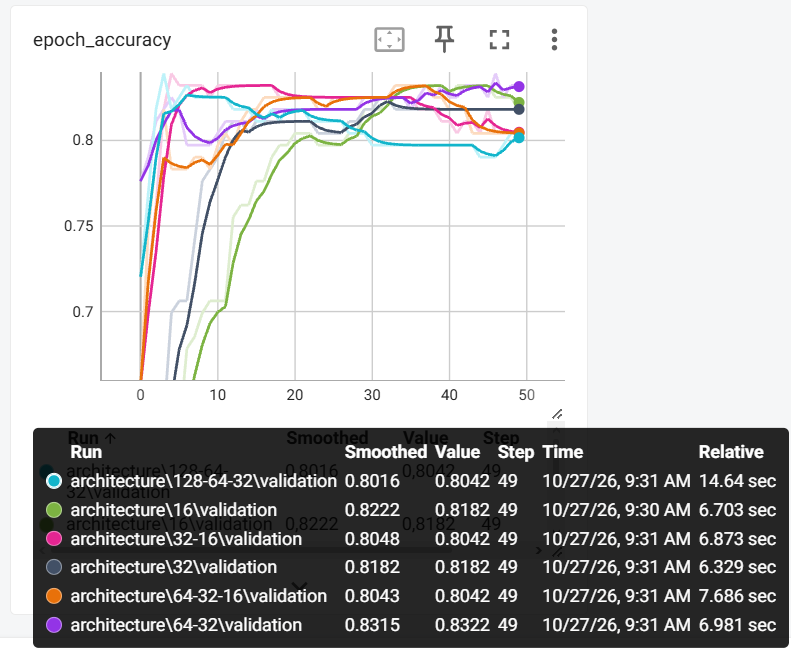

Изменение функции потерь на валидационной выборке при различных архитектурах нейронной сети.

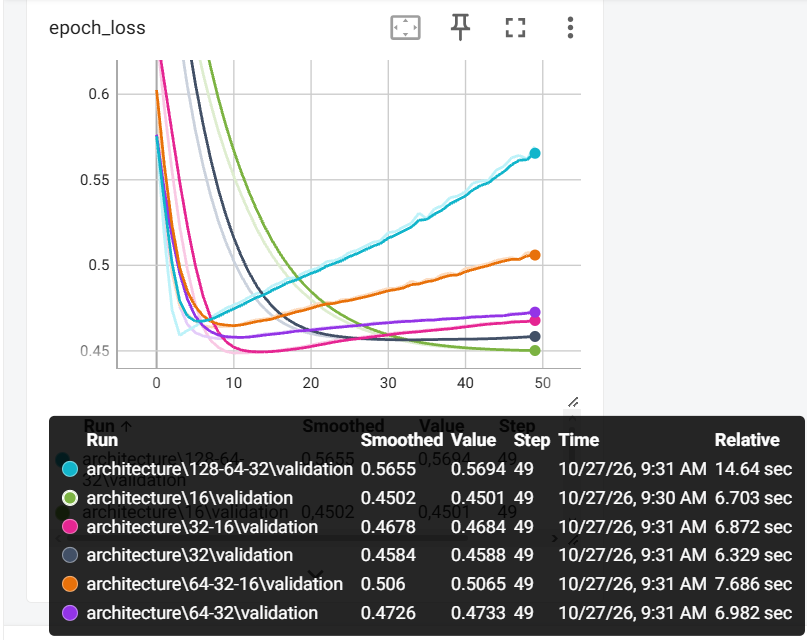

### Вывод

Увеличение сложности архитектуры сопровождается повышением точности на обучающей выборке. Максимальное значение Train Accuracy (0.8981) достигнуто моделью с архитектурой 128–64–32, содержащей 11905 обучаемых параметров. Однако на валидационной выборке данная модель показала точность 0.8042 и наибольшее значение функции потерь 0.5694, что свидетельствует о выраженном переобучении.

Наибольшая валидационная точность 0.8322 получена при архитектуре 64–32, содержащей два скрытых слоя. При этом минимальное значение Validation Loss (0.4501) достигнуто наиболее простой моделью с одним скрытым слоем из 16 нейронов.

Таким образом, увеличение количества скрытых слоёв и нейронов не гарантирует повышения качества классификации. Более сложные архитектуры могут сильнее подстраиваться под обучающие данные, что отрицательно сказывается на их обобщающей способности. Для дальнейшего исследования выделены архитектуры 64–32 и 16 как наиболее перспективные по точности и функции потерь соответственно.

# Исследование влияния функций активации

Для оценки влияния функций активации на качество классификации проводится серия экспериментов с использованием ReLU, Tanh и Sigmoid в скрытых слоях нейронной сети.

Во всех экспериментах используется одинаковая архитектура с двумя скрытыми слоями (32 и 16 нейронов), оптимизатор Adam, количество эпох обучения 50 и размер батча 32.

Функция активации выходного слоя остаётся неизменной — Sigmoid, поскольку решается задача бинарной классификации.

In [80]:
activation_values = ['relu', 'tanh', 'sigmoid']
activation_results = []

for activation in activation_values:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(67)

    model_exp = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(16, activation=activation),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model_exp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f'logs/tensorboard/activation/{activation}',
        histogram_freq=1
    )

    history_exp = model_exp.fit(
        X_train_scaled,
        y_train_nn,
        epochs=50,
        batch_size=32,
        validation_data=(X_val_scaled, y_val),
        callbacks=[callback],
        verbose=0
    )

    activation_results.append({
        'Активация': activation,
        'Train Accuracy': history_exp.history['accuracy'][-1],
        'Validation Accuracy': history_exp.history['val_accuracy'][-1],
        'Train Loss': history_exp.history['loss'][-1],
        'Validation Loss': history_exp.history['val_loss'][-1]
    })

activation_results_df = pd.DataFrame(activation_results)
display(activation_results_df.round(4))

,Активация,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,relu,0.8612,0.8042,0.3468,0.4684
1,tanh,0.8348,0.8322,0.3744,0.4474
2,sigmoid,0.8155,0.7762,0.4264,0.4506


Изменение точности классификации на валидационной выборке при различных функциях активации

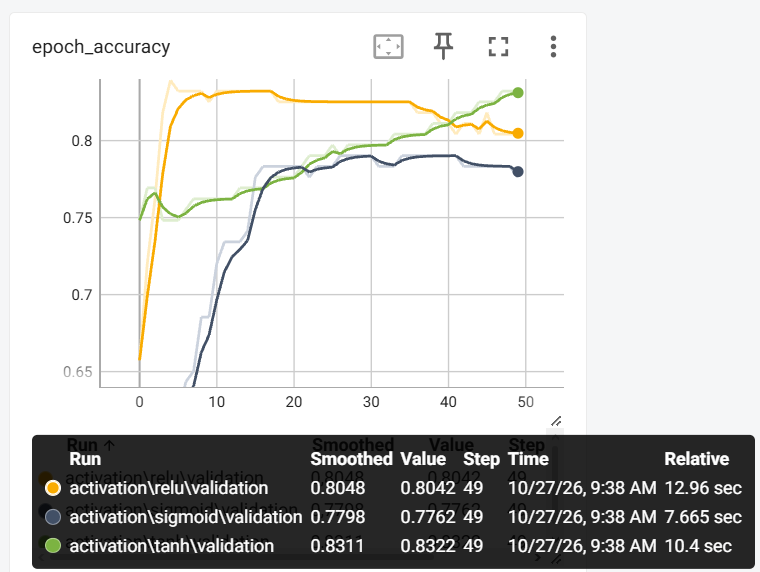

Изменение функции потерь на валидационной выборке при различных функциях активации

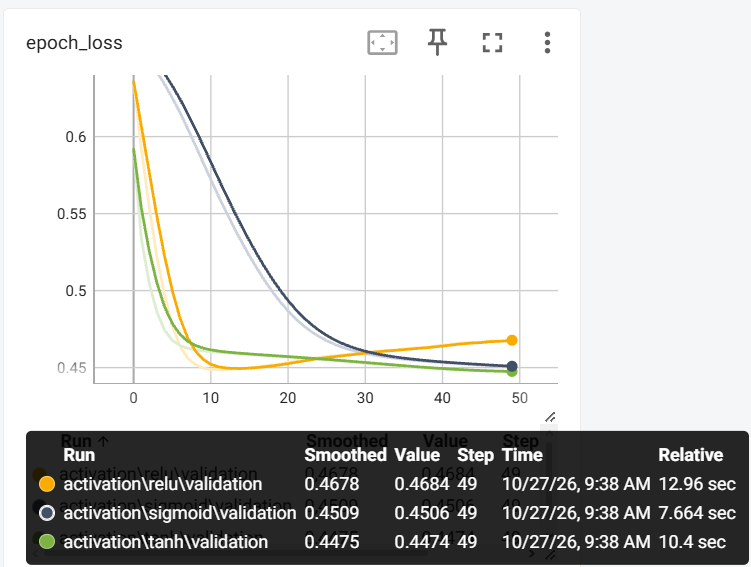

### Вывод

В ходе экспериментов исследовано влияние функций активации ReLU, Tanh и Sigmoid на качество классификации нейронной сети. Все эксперименты проводились при одинаковой архитектуре с двумя скрытыми слоями (32 и 16 нейронов), количестве эпох 50 и размере батча 32.

Установлено, что функция ReLU обеспечивает максимальную точность на обучающей выборке (0.8612) и минимальное значение Train Loss (0.3468). Однако на валидационной выборке точность составляет 0.8042, что указывает на возможное переобучение модели.

Наилучшие результаты на валидационной выборке получены при использовании функции Tanh. Точность классификации составила 0.8322, а значение функции потерь — 0.4474. При этом наблюдается минимальная разница между точностью на обучающей и валидационной выборках.

Функция Sigmoid показала наименьшую валидационную точность (0.7762), что делает её менее предпочтительной для рассматриваемой архитектуры.

Таким образом, среди исследованных функций активации наиболее подходящей оказалась Tanh, обеспечивающая максимальную точность классификации и минимальные потери на валидационной выборке.

Результаты экспериментов по изменению количества эпох, размера батча, архитектуры нейронной сети и функций активации сохранены в отдельных CSV-файлах.

In [81]:
os.makedirs('results', exist_ok=True)

epoch_results_df.to_csv('results/epochs.csv', index=False)
batch_results_df.to_csv('results/batch_size.csv', index=False)
architecture_results_df.to_csv('results/architecture.csv', index=False)
activation_results_df.to_csv('results/activation.csv', index=False)

# Автоматизированный подбор гиперпараметров нейронной сети

На основании результатов предыдущих экспериментов проводится дополнительное исследование совместного влияния гиперпараметров на качество классификации.

Для этого организован автоматизированный перебор 24 конфигураций нейронной сети, различающихся количеством эпох обучения, размером батча, архитектурой и функцией активации скрытых слоёв.

Для каждой конфигурации выполняется обучение на одинаковой обучающей выборке и оценка качества на валидационной выборке.

Параметры конфигураций и итоговые метрики сохраняются в общей таблице результатов с последующим экспортом в CSV-файл. История обучения каждой модели записывается в отдельный каталог TensorBoard, что позволяет сравнивать динамику изменения точности классификации и функции потерь.

Основным критерием выбора итоговой конфигурации является максимальная точность на валидационной выборке. При одинаковой точности дополнительно учитывается значение функции потерь.

In [82]:
epoch_values = [10, 25, 50]
batch_values = [32, 128]
architectures = [(16,), (64, 32)]
activation_values = ['relu', 'tanh']

final_results = []

os.makedirs('results', exist_ok=True)

for epochs, batch, architecture, activation in product(
    epoch_values, batch_values, architectures, activation_values
):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(67)

    model_exp = tf.keras.Sequential()
    model_exp.add(tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for neurons in architecture:
        model_exp.add(
            tf.keras.layers.Dense(neurons, activation=activation)
        )

    model_exp.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    model_exp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    architecture_name = '-'.join(map(str, architecture))

    run_name = (
        f'epochs_{epochs}_batch_{batch}_'
        f'arch_{architecture_name}_act_{activation}'
    )

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f'logs/tensorboard/final_search/{run_name}',
        histogram_freq=0
    )

    history_exp = model_exp.fit(
        X_train_scaled,
        y_train_nn,
        epochs=epochs,
        batch_size=batch,
        validation_data=(X_val_scaled, y_val),
        callbacks=[callback],
        verbose=0
    )

    final_results.append({
        'Эпохи': epochs,
        'Batch Size': batch,
        'Архитектура': architecture_name,
        'Активация': activation,
        'Train Accuracy': history_exp.history['accuracy'][-1],
        'Validation Accuracy': history_exp.history['val_accuracy'][-1],
        'Train Loss': history_exp.history['loss'][-1],
        'Validation Loss': history_exp.history['val_loss'][-1],
        'Run': run_name
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    by=['Validation Accuracy', 'Validation Loss'],
    ascending=[False, True]
).reset_index(drop=True)

final_results_df.to_csv(
    'results/final_search_results.csv',
    index=False,
    encoding='utf-8-sig'
)

display(final_results_df.round(4))

,Эпохи,Batch Size,Архитектура,Активация,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss,Run
0,50,128,64-32,tanh,0.8330,0.8322,0.3956,0.4552,epochs_50_batch_128_arch_64-32_act_tanh
1,50,32,64-32,relu,0.8612,0.8322,0.3236,0.4733,epochs_50_batch_32_arch_64-32_act_relu
2,50,32,16,relu,0.8436,0.8182,0.3781,0.4501,epochs_50_batch_32_arch_16_act_relu
3,25,32,64-32,relu,0.8506,0.8182,0.3522,0.4643,epochs_25_batch_32_arch_64-32_act_relu
4,50,32,64-32,tanh,0.8471,0.8182,0.3576,0.4653,epochs_50_batch_32_arch_64-32_act_tanh
5,50,128,64-32,relu,0.8541,0.8182,0.3487,0.4724,epochs_50_batch_128_arch_64-32_act_relu
6,10,128,64-32,relu,0.8120,0.8112,0.4261,0.4734,epochs_10_batch_128_arch_64-32_act_relu
7,25,128,64-32,relu,0.8313,0.8042,0.3772,0.4565,epochs_25_batch_128_arch_64-32_act_relu
8,50,32,16,tanh,0.8207,0.8042,0.4105,0.4583,epochs_50_batch_32_arch_16_act_tanh
9,25,32,64-32,tanh,0.8278,0.7972,0.3957,0.4564,epochs_25_batch_32_arch_64-32_act_tanh


### Вывод

В ходе дополнительного эксперимента проведён автоматизированный перебор 24 конфигураций нейронной сети, различающихся количеством эпох обучения, размером батча, архитектурой и функцией активации.

Установлено, что наилучшие значения отдельных гиперпараметров не всегда обеспечивают максимальное качество классификации при совместном использовании. В частности, комбинация из 10 эпох, размера батча 128, архитектуры 64–32 и функции Tanh показала валидационную точность 0.7832. При увеличении количества эпох до 50 точность возросла до 0.8322.

Максимальная валидационная точность 0.8322 достигнута двумя конфигурациями. При этом модель с 50 эпохами, размером батча 128, архитектурой 64–32 и функцией активации Tanh продемонстрировала меньшее значение функции потерь (0.4552), чем альтернативная конфигурация с ReLU (0.4733).

Таким образом, в качестве итоговой выбрана нейронная сеть с двумя скрытыми слоями по 64 и 32 нейрона, функцией активации Tanh, размером батча 128 и количеством эпох обучения 50.

Сравнение валидационной точности модели, составленной из лучших гиперпараметров отдельных экспериментов, и итоговой модели.

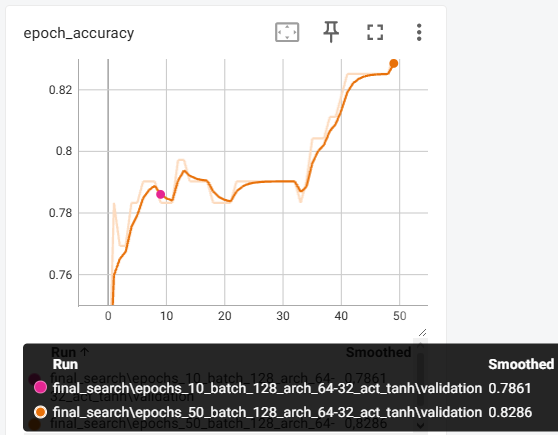

Сравнение валидационной функции потерь модели, составленной из лучших гиперпараметров отдельных экспериментов, и итоговой модели.

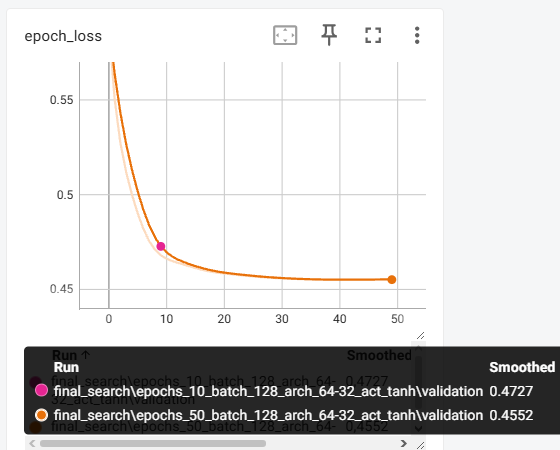

### Оценка итоговой нейронной сети на тестовой выборке

После подбора гиперпараметров проводится оценка итоговой нейронной сети на тестовой выборке, которая не использовалась при обучении и выборе конфигурации модели.

Итоговая нейронная сеть содержит два скрытых слоя с 64 и 32 нейронами, использует функцию активации Tanh, оптимизатор Adam, размер батча 128 и обучается в течение 50 эпох.

Для оценки качества классификации рассчитываются метрики Accuracy, Precision, Recall, F1-score и ROC-AUC. Дополнительно строятся матрица ошибок и ROC-кривая.

### Обучение итоговой модели

In [83]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(67)

final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation='tanh'),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

final_history = final_model.fit(
    X_train_scaled,
    y_train_nn,
    epochs=50,
    batch_size=128,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

In [84]:
y_proba = final_model.predict(X_test_scaled).ravel()

y_pred = (y_proba >= 0.5).astype(int)

nn_results = pd.DataFrame([{
    'Model': 'Neural Network',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
}])

display(nn_results.round(4))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Neural Network,0.7821,0.7419,0.6667,0.7023,0.836


### Матрица ошибок

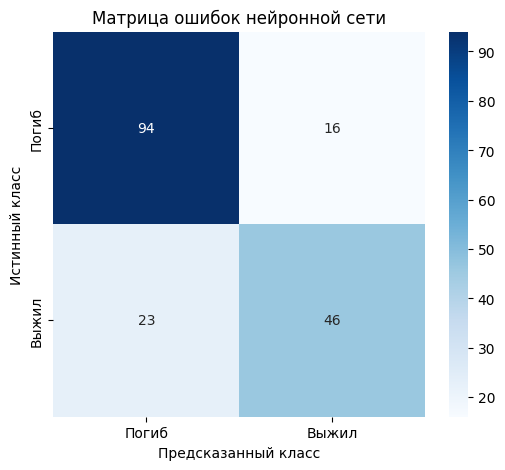

In [85]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Погиб', 'Выжил'],
    yticklabels=['Погиб', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок нейронной сети')

plt.show()

### ROC-кривая

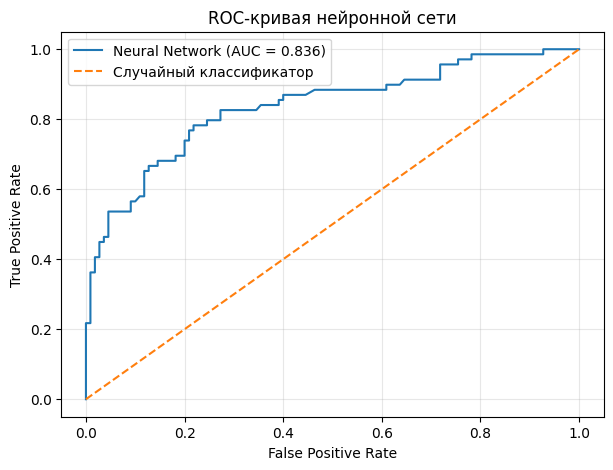

In [86]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Neural Network (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', label='Случайный классификатор')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая нейронной сети')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Вывод

Проведена оценка итоговой нейронной сети на тестовой выборке, не использовавшейся при обучении и подборе гиперпараметров.

Точность классификации составила 0.7821, Precision — 0.7419, Recall — 0.6667, F1-score — 0.7023, ROC-AUC — 0.8360.

Полученные результаты показывают, что модель правильно классифицирует около 78% пассажиров тестовой выборки. При этом Recall составляет 66.67%, что указывает на наличие ошибок при распознавании выживших пассажиров.

Значение ROC-AUC 0.8360 свидетельствует о способности модели различать классы при различных порогах классификации.

Таким образом, итоговая нейронная сеть продемонстрировала приемлемое качество бинарной классификации пассажиров «Титаника». В ходе работы исследовано влияние основных гиперпараметров на процесс обучения, выполнен подбор итоговой конфигурации и проведена оценка её качества на независимой тестовой выборке.